In [ ]:

# STEP 1: Set up our NLP project

%pip -q install pandas numpy scikit-learn matplotlib

import pandas as pd
import numpy as np
import sklearn
import sys

print("NLP Project: Kannada-English Sentiment Analysis")
print("-----------------------------------------------")
print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("\nSetup completed successfully!")


NLP Project: Kannada-English Sentiment Analysis
-----------------------------------------------
Python version: 3.13.16
Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1

Setup completed successfully!


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving DravidianCodeMix-2020.zip to DravidianCodeMix-2020.zip


In [ ]:

import zipfile

zip_path = "/content/DravidianCodeMix-2020.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    dataset_files = [
        name for name in z.namelist()
        if name.lower().endswith((".csv", ".tsv"))
    ]

print("Number of CSV/TSV files:", len(dataset_files))
print("\nFiles available:")
for name in dataset_files:
    print(name)


Number of CSV/TSV files: 24

Files available:
DravidianCodeMix/tamil_sentiment_full_train.csv
DravidianCodeMix/tamil_sentiment_full.csv
DravidianCodeMix/tamil_offensive_full_train.csv
DravidianCodeMix/tamil_offensive_full_test.csv
DravidianCodeMix/tamil_offensive_full_dev.csv
DravidianCodeMix/tamil_offensive_full.csv
DravidianCodeMix/mal_full_sentiment_train.csv
DravidianCodeMix/mal_full_sentiment_test.csv
DravidianCodeMix/mal_full_sentiment_dev.csv
DravidianCodeMix/mal_full_sentiment.tsv
DravidianCodeMix/mal_full_offensive_train.csv
DravidianCodeMix/kannada_sentiment_train.csv
DravidianCodeMix/kannada_sentiment_test.csv
DravidianCodeMix/kannada_sentiment_dev.csv
DravidianCodeMix/kannada_offensive_train.csv
DravidianCodeMix/kannada_offensive_test.csv
DravidianCodeMix/kannada_offensive_dev.csv
DravidianCodeMix/mal_full_offensive_test.csv
DravidianCodeMix/mal_full_offensive_dev.csv
DravidianCodeMix/mal_full_offensive.csv
DravidianCodeMix/kannada_offensive.csv
DravidianCodeMix/kannada_sen

In [ ]:

# Step 6: Prepare sentiment datasets

# Keep the four sentiment labels and exclude not-Kannada
valid_labels = [
    "Positive",
    "Negative",
    "Mixed_feelings",
    "unknown_state"
]

clean_datasets = {}

for split, df in datasets.items():
    cleaned = df.copy()

    # Remove rows outside the sentiment task
    cleaned = cleaned[cleaned["sentiment"].isin(valid_labels)].copy()

    # Normalize extra whitespace in comments
    cleaned["text"] = cleaned["text"].astype(str).str.strip()
    cleaned = cleaned[cleaned["text"] != ""]

    clean_datasets[split] = cleaned.reset_index(drop=True)

    print(f"\n{split.upper()} SET")
    print("Rows retained:", len(cleaned))
    print("Sentiment distribution:")
    print(cleaned["sentiment"].value_counts().to_string())

print("\nExample cleaned comments:")
print(
    clean_datasets["train"][["text", "sentiment"]]
    .sample(min(5, len(clean_datasets["train"])), random_state=42)
    .to_string(index=False)
)



TRAIN SET
Rows retained: 5218
Sentiment distribution:
sentiment
Positive          2813
Negative          1182
unknown_state      676
Mixed_feelings     547

DEV SET
Rows retained: 656
Sentiment distribution:
sentiment
Positive          347
Negative          158
unknown_state      80
Mixed_feelings     71

TEST SET
Rows retained: 661
Sentiment distribution:
sentiment
Positive          358
Negative          144
unknown_state      86
Mixed_feelings     73

Example cleaned comments:
                                                                                                            text      sentiment
                                                           Sir e Corona effect mugidmele rerelease maadakaagalva Mixed_feelings
                                                                               Nejwad deushya torishi eg heliddu       Negative
Super sir nim anthoru Nam Kannada industry ge beku namma Kannada industrya kirty patake ellade harabeku belibeku       Positive
   

In [ ]:

# Step 7: Check data quality

for split, df in clean_datasets.items():
    print(f"\n{split.upper()} DATA CHECK")
    print("Total rows:", len(df))
    print("Missing text:", df["text"].isna().sum())
    print("Missing labels:", df["sentiment"].isna().sum())
    print("Unexpected labels:")
    print(
        df.loc[
            ~df["sentiment"].isin([
                "Positive", "Negative",
                "Mixed_feelings", "unknown_state"
            ]),
            "sentiment"
        ].value_counts().to_dict()
    )

    print("Empty comments:", (df["text"].str.strip() == "").sum())



TRAIN DATA CHECK
Total rows: 5218
Missing text: 0
Missing labels: 0
Unexpected labels:
{}
Empty comments: 0

DEV DATA CHECK
Total rows: 656
Missing text: 0
Missing labels: 0
Unexpected labels:
{}
Empty comments: 0

TEST DATA CHECK
Total rows: 661
Missing text: 0
Missing labels: 0
Unexpected labels:
{}
Empty comments: 0


In [ ]:

# Step 8: Final dataset sanity check

for split, df in clean_datasets.items():
    print(f"\n{split.upper()}")
    print("Rows:", len(df))
    print("Unique labels:", sorted(df["sentiment"].unique()))
    print("Duplicate comments:", df["text"].duplicated().sum())
    print("Text length (characters):")
    print(df["text"].str.len().describe().round(1).to_string())



TRAIN
Rows: 5218
Unique labels: ['Mixed_feelings', 'Negative', 'Positive', 'unknown_state']
Duplicate comments: 192
Text length (characters):
count    5218.0
mean       55.7
std        59.5
min         4.0
25%        22.0
50%        38.0
75%        64.0
max       772.0

DEV
Rows: 656
Unique labels: ['Mixed_feelings', 'Negative', 'Positive', 'unknown_state']
Duplicate comments: 13
Text length (characters):
count    656.0
mean      52.5
std       51.9
min        7.0
25%       23.0
50%       36.0
75%       63.0
max      535.0

TEST
Rows: 661
Unique labels: ['Mixed_feelings', 'Negative', 'Positive', 'unknown_state']
Duplicate comments: 5
Text length (characters):
count    661.0
mean      57.3
std       62.6
min        3.0
25%       23.0
50%       39.0
75%       64.0
max      595.0


In [ ]:

# Step 9: Baseline NLP model
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

train_df = clean_datasets["train"]
dev_df = clean_datasets["dev"]

# Convert text into TF-IDF features
vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

X_train = vectorizer.fit_transform(train_df["text"])
X_dev = vectorizer.transform(dev_df["text"])

y_train = train_df["sentiment"]
y_dev = dev_df["sentiment"]

# Train classifier
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

# Evaluate on the validation set
dev_predictions = model.predict(X_dev)

print("Validation Accuracy:",
      round(accuracy_score(y_dev, dev_predictions), 4))

print("Validation Macro-F1:",
      round(f1_score(y_dev, dev_predictions, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(
    y_dev, dev_predictions, zero_division=0
))


Validation Accuracy: 0.5945
Validation Macro-F1: 0.5077

Classification Report:
                precision    recall  f1-score   support

Mixed_feelings       0.24      0.32      0.28        71
      Negative       0.58      0.58      0.58       158
      Positive       0.82      0.67      0.74       347
 unknown_state       0.36      0.55      0.44        80

      accuracy                           0.59       656
     macro avg       0.50      0.53      0.51       656
  weighted avg       0.65      0.59      0.61       656



In [ ]:

# Compare current row counts with the original archive
import zipfile

zip_path = "/content/DravidianCodeMix-2020.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    for filename in [
        "DravidianCodeMix/kannada_sentiment_train.csv",
        "DravidianCodeMix/kannada_sentiment_dev.csv",
        "DravidianCodeMix/kannada_sentiment_test.csv"
    ]:
        with z.open(filename) as f:
            raw_lines = f.read().decode(
                "utf-8", errors="replace"
            ).splitlines()

        print(filename, "raw lines:", len(raw_lines))


DravidianCodeMix/kannada_sentiment_train.csv raw lines: 6136
DravidianCodeMix/kannada_sentiment_dev.csv raw lines: 767
DravidianCodeMix/kannada_sentiment_test.csv raw lines: 768


In [ ]:
# Check the labels in each dataset
for split, df in datasets.items():
    print(f"\n{split.upper()} — original parsed data")
    print(df["sentiment"].value_counts(dropna=False))
    print("Total parsed rows:", len(df))


TRAIN — original parsed data
sentiment
Positive          2813
Negative          1182
not-Kannada        918
unknown_state      676
Mixed_feelings     547
Name: count, dtype: int64
Total parsed rows: 6136

DEV — original parsed data
sentiment
Positive          347
Negative          158
not-Kannada       111
unknown_state      80
Mixed_feelings     71
Name: count, dtype: int64
Total parsed rows: 767

TEST — original parsed data
sentiment
Positive          358
Negative          144
not-Kannada       107
unknown_state      86
Mixed_feelings     73
Name: count, dtype: int64
Total parsed rows: 768


In [ ]:
for split, df in clean_datasets.items():
    print(f"\n{split.upper()}")
    print("Total usable comments:", len(df))
    print(df["sentiment"].value_counts())


TRAIN
Total usable comments: 5218
sentiment
Positive          2813
Negative          1182
unknown_state      676
Mixed_feelings     547
Name: count, dtype: int64

DEV
Total usable comments: 656
sentiment
Positive          347
Negative          158
unknown_state      80
Mixed_feelings     71
Name: count, dtype: int64

TEST
Total usable comments: 661
sentiment
Positive          358
Negative          144
unknown_state      86
Mixed_feelings     73
Name: count, dtype: int64


In [ ]:
# Check overlap between training and development comments
train_texts = set(clean_datasets["train"]["text"].str.strip().str.lower())
dev_texts = set(clean_datasets["dev"]["text"].str.strip().str.lower())

overlap = train_texts.intersection(dev_texts)

print("Unique training comments:", len(train_texts))
print("Unique development comments:", len(dev_texts))
print("Comments appearing in both:", len(overlap))

Unique training comments: 5005
Unique development comments: 643
Comments appearing in both: 23


In [ ]:
# Display up to 10 comments shared by train and development
overlap_examples = clean_datasets["train"][
    clean_datasets["train"]["text"].str.strip().str.lower().isin(overlap)
][["text", "sentiment"]].drop_duplicates()

print("Number of overlapping training rows:", len(overlap_examples))
display(overlap_examples.head(10))

Number of overlapping training rows: 41


,text,sentiment
21,ಚಂದನ್ ಶೆಟ್ಟಿ ಟ್ರೊಲ್ ವಿಡಿಯೋ ನೀವು ನೋಡಿ ನೆಗಡ್ಡೆ ಇ...,Positive
89,Anna super Anna,Positive
170,jai d boss,Positive
204,super togari tippa,Positive
264,ಇದು ಚರಿತ್ರೆ ಸೃಷ್ಟಿಸೋ ಅವತಾರ,Positive
289,Super song,Positive
296,GTA 5 bro,unknown_state
302,Hands up,unknown_state
319,jai d boss,unknown_state
331,Super guru,Positive


Baseline Model Evaluation
Accuracy: 0.5945
Macro F1-Score: 0.5077

Classification Report:
                precision    recall  f1-score   support

Mixed_feelings       0.24      0.32      0.28        71
      Negative       0.58      0.58      0.58       158
      Positive       0.82      0.67      0.74       347
 unknown_state       0.36      0.55      0.44        80

      accuracy                           0.59       656
     macro avg       0.50      0.53      0.51       656
  weighted avg       0.65      0.59      0.61       656



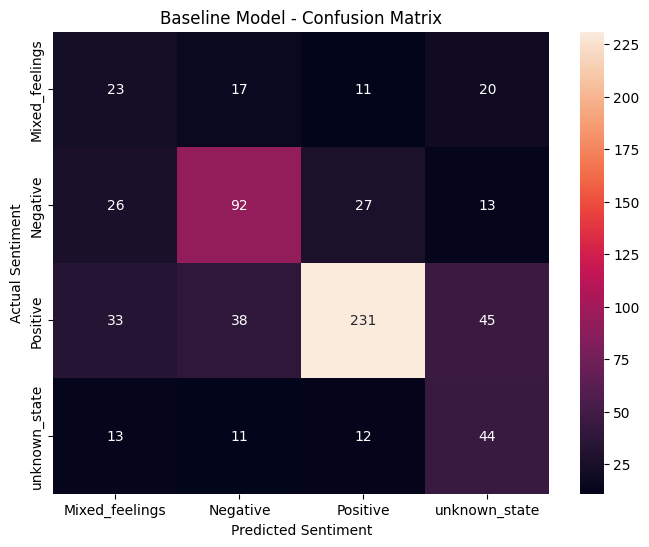

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predict sentiment for the development dataset
dev_predictions = model.predict(X_dev)

# Calculate evaluation metrics
print("Baseline Model Evaluation")
print("Accuracy:", round(accuracy_score(y_dev, dev_predictions), 4))
print("Macro F1-Score:", round(
    f1_score(y_dev, dev_predictions, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(y_dev, dev_predictions, zero_division=0))

# Plot the confusion matrix
labels = model.classes_
cm = confusion_matrix(y_dev, dev_predictions, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels
)
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Baseline Model - Confusion Matrix")
plt.show()

In [ ]:
!pip -q install transformers datasets accelerate scikit-learn

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Tokenizer loaded successfully!
PyTorch version: 2.11.0+cpu
GPU available: False


In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [ ]:
print("Dataset available:", "clean_datasets" in globals())
print("Baseline model available:", "model" in globals())
print("Tokenizer available:", "tokenizer" in globals())

Dataset available: False
Baseline model available: False
Tokenizer available: False


In [ ]:
import os

zip_path = "/content/DravidianCodeMix-2020.zip"

print("Dataset ZIP exists:", os.path.exists(zip_path))

Dataset ZIP exists: False


In [ ]:
import os
print(os.listdir("/content"))

['.config', 'DravidianCodeMix-2020.zip', 'sample_data']


In [ ]:
import zipfile
import pandas as pd

zip_path = "/content/DravidianCodeMix-2020.zip"
files = {
    "train": "DravidianCodeMix/kannada_sentiment_train.csv",
    "dev": "DravidianCodeMix/kannada_sentiment_dev.csv",
    "test": "DravidianCodeMix/kannada_sentiment_test.csv"
}

clean_datasets = {}

with zipfile.ZipFile(zip_path) as z:
    for split, filename in files.items():
        with z.open(filename) as f:
            lines = f.read().decode("utf-8-sig", errors="replace").splitlines()

        rows = []
        for line in lines:
            parts = line.split(";")
            while parts and not parts[-1].strip():
                parts.pop()
            if len(parts) >= 2:
                label = parts[-1].strip()
                text = ";".join(parts[:-1]).strip()
                if text and label in [
                    "Positive", "Negative",
                    "Mixed_feelings", "unknown_state"
                ]:
                    rows.append({"text": text, "sentiment": label})

        clean_datasets[split] = pd.DataFrame(rows)

print("Train:", len(clean_datasets["train"]))
print("Development:", len(clean_datasets["dev"]))
print("Test:", len(clean_datasets["test"]))
print("Dataset restored successfully!")

Train: 5218
Development: 656
Test: 661
Dataset restored successfully!


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "bert-base-multilingual-cased"
labels = sorted(clean_datasets["train"]["sentiment"].unique())

tokenizer = AutoTokenizer.from_pretrained(model_name)
transformer_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(labels)
).to("cuda")

print("Transformer loaded!")
print("Labels:", labels)
print("GPU:", torch.cuda.get_device_name(0))

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Transformer loaded!
Labels: ['Mixed_feelings', 'Negative', 'Positive', 'unknown_state']
GPU: Tesla T4


In [ ]:
import numpy as np
from transformers import Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, f1_score

label2id = {label: i for i, label in enumerate(labels)}

def prepare_data(df):
    enc = tokenizer(
        df["text"].tolist(),
        truncation=True,
        padding="max_length",
        max_length=96
    )
    enc["labels"] = [label2id[x] for x in df["sentiment"]]
    return enc

class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, enc):
        self.enc = enc
    def __len__(self):
        return len(self.enc["labels"])
    def __getitem__(self, i):
        return {k: torch.tensor(v[i]) for k, v in self.enc.items()}

train_data = SentimentDataset(prepare_data(clean_datasets["train"]))
dev_data = SentimentDataset(prepare_data(clean_datasets["dev"]))

args = TrainingArguments(
    output_dir="/content/bert_results",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    fp16=True
)

trainer = Trainer(
    model=transformer_model,
    args=args,
    train_dataset=train_data,
    eval_dataset=dev_data,
    compute_metrics=lambda p: {
        "accuracy": accuracy_score(p.label_ids, np.argmax(p.predictions, axis=1)),
        "macro_f1": f1_score(p.label_ids, np.argmax(p.predictions, axis=1), average="macro")
    }
)

trainer.train()
print(trainer.evaluate())

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.049689,0.881910,0.657012,0.480486
2,0.848746,0.863522,0.678354,0.511217


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.848746,0.863522,2,0.678354,0.511217


{'eval_loss': 0.8635222911834717, 'eval_accuracy': 0.6783536585365854, 'eval_macro_f1': 0.5112168780400519}


In [ ]:
test_data = SentimentDataset(prepare_data(clean_datasets["test"]))
print(trainer.evaluate(test_data))

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.848746,0.884581,2,0.692890,0.514560


{'eval_loss': 0.884580671787262, 'eval_accuracy': 0.6928895612708018, 'eval_macro_f1': 0.5145597281583741}


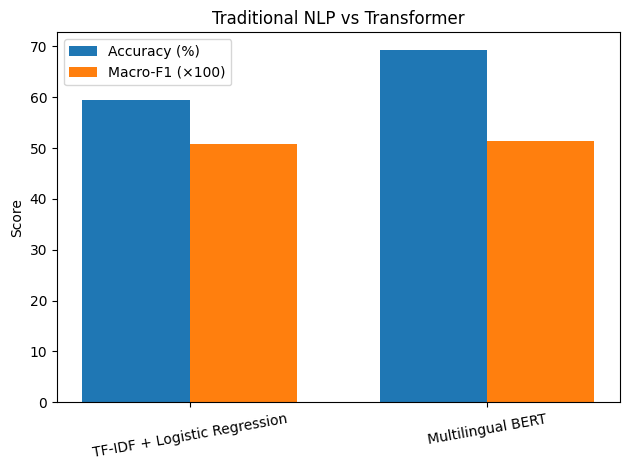

In [ ]:
import matplotlib.pyplot as plt

models = ["TF-IDF + Logistic Regression", "Multilingual BERT"]
accuracy = [59.45, 69.29]
macro_f1 = [0.5077, 0.5146]

x = range(len(models))
plt.bar([i - 0.18 for i in x], accuracy, width=0.36, label="Accuracy (%)")
plt.bar([i + 0.18 for i in x], [v * 100 for v in macro_f1],
        width=0.36, label="Macro-F1 (×100)")
plt.xticks(list(x), models, rotation=10)
plt.ylabel("Score")
plt.title("Traditional NLP vs Transformer")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Compare original test comments with lightly altered versions
test_df = clean_datasets["test"].copy()
noisy_df = test_df.copy()
noisy_df["text"] = noisy_df["text"].str.replace(" ", "  ", regex=False)

original_data = SentimentDataset(prepare_data(test_df))
noisy_data = SentimentDataset(prepare_data(noisy_df))

original_pred = trainer.predict(original_data).predictions.argmax(axis=1)
noisy_pred = trainer.predict(noisy_data).predictions.argmax(axis=1)
true_labels = [label2id[x] for x in test_df["sentiment"]]

print("Original accuracy:", round(accuracy_score(true_labels, original_pred), 4))
print("Altered-text accuracy:", round(accuracy_score(true_labels, noisy_pred), 4))
print("Original macro-F1:", round(f1_score(true_labels, original_pred, average="macro"), 4))
print("Altered macro-F1:", round(f1_score(true_labels, noisy_pred, average="macro"), 4))

Original accuracy: 0.6929
Altered-text accuracy: 0.6929
Original macro-F1: 0.5146
Altered macro-F1: 0.5146


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Train the traditional model
train_df = clean_datasets["train"]
test_df = clean_datasets["test"]

vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2)
X_train = vectorizer.fit_transform(train_df["text"])
X_test = vectorizer.transform(test_df["text"])

baseline = LogisticRegression(
    max_iter=1000, class_weight="balanced", random_state=42
)
baseline.fit(X_train, train_df["sentiment"])
baseline_pred = baseline.predict(X_test)

# Get BERT predictions on the same test set
bert_pred_ids = trainer.predict(test_data).predictions.argmax(axis=1)
bert_pred = [labels[i] for i in bert_pred_ids]

# Compare both models
results = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression", "Multilingual BERT"],
    "Test Accuracy": [
        accuracy_score(test_df["sentiment"], baseline_pred),
        accuracy_score(test_df["sentiment"], bert_pred)
    ],
    "Test Macro-F1": [
        f1_score(test_df["sentiment"], baseline_pred, average="macro"),
        f1_score(test_df["sentiment"], bert_pred, average="macro")
    ]
})

display(results.round(4))

,Model,Test Accuracy,Test Macro-F1
0,TF-IDF + Logistic Regression,0.5946,0.5078
1,Multilingual BERT,0.6929,0.5146


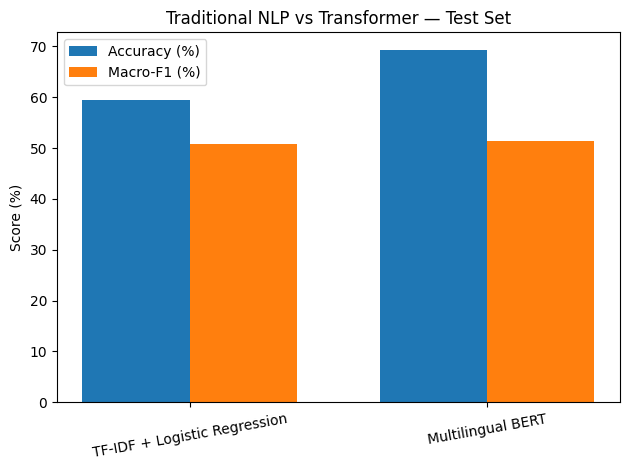

In [ ]:
import matplotlib.pyplot as plt

models = ["TF-IDF + Logistic Regression", "Multilingual BERT"]
accuracy = [59.46, 69.29]
macro_f1 = [50.78, 51.46]  # Macro-F1 converted to percentage

x = range(len(models))
plt.bar([i - 0.18 for i in x], accuracy, width=0.36, label="Accuracy (%)")
plt.bar([i + 0.18 for i in x], macro_f1, width=0.36, label="Macro-F1 (%)")

plt.xticks(list(x), models, rotation=10)
plt.ylabel("Score (%)")
plt.title("Traditional NLP vs Transformer — Test Set")
plt.legend()
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()